# UAS IS411 Data Modelling  
## Prediksi Arah Pergerakan Harga Saham IDX Hari Perdagangan Berikutnya Menggunakan CRISP-DM

**Dataset:** `Salinan IDX.csv`  
**Metodologi:** CRISP-DM  
**Jenis masalah:** Binary Classification  
**Target:**  
- `1` = harga penutupan saham pada hari perdagangan berikutnya naik  
- `0` = harga penutupan saham pada hari perdagangan berikutnya turun atau tetap  

---

## Pengembangan dari Proyek Sebelumnya

Notebook ini dikembangkan dari proyek klasifikasi saham IDX sebelumnya, tetapi dibuat lebih lengkap agar sesuai dengan kebutuhan UAS:

1. Target diperbaiki menjadi **pergerakan harga pada hari perdagangan berikutnya**, bukan perubahan harga pada hari yang sama.
2. Pembagian data dilakukan secara **kronologis** untuk menghindari kebocoran informasi dari masa depan.
3. Ditambahkan **feature engineering** berbasis harga, volume, volatilitas, moving average, dan aktivitas investor asing.
4. Ditambahkan **Dummy Baseline**, **Logistic Regression**, **Decision Tree**, serta dua konfigurasi **Random Forest**.
5. Evaluasi menggunakan accuracy, balanced accuracy, precision, recall, F1-score, ROC-AUC, confusion matrix, dan ROC curve.
6. Ditambahkan proses pemilihan threshold, feature importance, penyimpanan model, dan simulasi deployment.



# Pemetaan Tahapan CRISP-DM

| Tahap CRISP-DM | Implementasi pada Notebook |
|---|---|
| 1. Business Understanding | Menentukan masalah bisnis, tujuan prediksi, target, dan batasan |
| 2. Data Understanding | Membaca dataset, memeriksa struktur data, duplikasi, missing value, distribusi, dan outlier |
| 3. Data Preparation | Membersihkan data, mengubah tanggal, menghapus duplikasi, membuat fitur, menangani nilai ekstrem |
| 4. Modelling | Membandingkan baseline, Logistic Regression, Decision Tree, dan Random Forest |
| 5. Evaluation | Mengevaluasi model dengan berbagai metrik serta memilih model terbaik |
| 6. Deployment | Menyimpan model dan membuat fungsi simulasi prediksi saham terbaru |


# 1. Business Understanding

## Latar Belakang
Pergerakan harga saham bersifat dinamis dan dipengaruhi oleh berbagai indikator perdagangan. Dataset IDX menyediakan informasi historis seperti harga sebelumnya, harga tertinggi, harga terendah, harga penutupan, volume transaksi, nilai transaksi, frekuensi transaksi, serta aktivitas beli dan jual investor asing.

## Rumusan Masalah
Bagaimana membangun model machine learning yang dapat memperkirakan apakah harga penutupan saham akan naik pada hari perdagangan berikutnya berdasarkan informasi yang sudah tersedia pada akhir hari perdagangan saat ini?

## Tujuan
1. Mengolah data historis saham IDX secara sistematis menggunakan CRISP-DM.
2. Membuat fitur yang relevan untuk prediksi arah harga saham hari perdagangan berikutnya.
3. Membandingkan beberapa algoritma klasifikasi.
4. Memilih model terbaik berdasarkan ROC-AUC dan metrik pendukung.
5. Membuat simulasi deployment sederhana.

## Batasan
1. Prediksi hanya menggunakan informasi perdagangan historis dalam dataset.
2. Model belum menggunakan berita, kondisi makroekonomi, sentimen pasar, aksi korporasi, atau laporan keuangan.
3. Prediksi dilakukan untuk kebutuhan akademik dan bukan rekomendasi jual atau beli saham.


In [1]:
# ============================================================
# Import library dan konfigurasi
# ============================================================

import os
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
GENERAL_SAMPLE_ROWS = 40_000
RF_SAMPLE_ROWS = 30_000

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Library berhasil di-import.")


Library berhasil di-import.


# 2. Data Understanding

Pada tahap ini dilakukan pemeriksaan awal dataset: jumlah baris, jumlah kolom, nama variabel, tipe data, periode data, jumlah saham, missing value, duplikasi, dan proporsi nilai nol.


In [2]:
# ============================================================
# Menentukan lokasi dataset
# ============================================================

DATASET_CANDIDATES = [
    "Salinan IDX.csv",
    "/content/Salinan IDX.csv",
    "/mnt/data/Salinan IDX.csv",
]

DATASET_PATH = next((path for path in DATASET_CANDIDATES if os.path.exists(path)), None)

if DATASET_PATH is None:
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Upload file 'Salinan IDX.csv' ke folder kerja notebook."
    )

print("Dataset ditemukan:", DATASET_PATH)


Dataset ditemukan: Salinan IDX.csv


In [3]:
# ============================================================
# Membaca dataset mentah
# ============================================================

raw_df = pd.read_csv(DATASET_PATH)

print("Ukuran dataset mentah:", raw_df.shape)
display(raw_df.head())


Ukuran dataset mentah: (831622, 14)


,Stock Code,Company Name,Last Trading Date,Previous,Open Price,High,Low,Close,Change,Volume,Value,Frequency,Foreign Sell,Foreign Buy
0,AALI,Astra Agro Lestari Tbk.,02 Jan 2020,"14,575.0000",0.0000,"14,650.0000","14,025.0000","14,025.0000",-550.0000,"799,000.0000","11,451,335,000.0000",888.0000,"106,300.0000","253,800.0000"
1,ABBA,Mahaka Media Tbk.,02 Jan 2020,106.0000,0.0000,108.0000,105.0000,105.0000,-1.0000,"6,340,800.0000","671,926,200.0000",624.0000,"21,600.0000",0.0000
2,ABDA,Asuransi Bina Dana Arta Tbk.,02 Jan 2020,"6,975.0000",0.0000,"7,075.0000","6,925.0000","6,925.0000",-50.0000,"1,700.0000","12,012,500.0000",6.0000,"1,600.0000",0.0000
3,ABMM,ABM Investama Tbk.,02 Jan 2020,"1,530.0000",0.0000,0.0000,0.0000,"1,530.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,ACES,Ace Hardware Indonesia Tbk.,02 Jan 2020,"1,495.0000",0.0000,"1,535.0000","1,500.0000","1,510.0000",15.0000,"13,727,900.0000","20,813,083,000.0000","3,295.0000","7,584,400.0000","5,264,200.0000"


In [4]:
# ============================================================
# Audit struktur dataset
# ============================================================

print("Nama kolom:")
print(raw_df.columns.tolist())

print("\nTipe data:")
display(raw_df.dtypes.to_frame("dtype"))

print("\nMissing value:")
display(raw_df.isna().sum().to_frame("missing_value"))

print("\nJumlah duplikasi baris:", raw_df.duplicated().sum())


Nama kolom:
['Stock Code', 'Company Name', 'Last Trading Date', 'Previous', 'Open Price', 'High', 'Low', 'Close', 'Change', 'Volume', 'Value', 'Frequency', 'Foreign Sell', 'Foreign Buy']

Tipe data:


,dtype
Stock Code,object
Company Name,object
Last Trading Date,object
Previous,float64
Open Price,float64
High,float64
Low,float64
Close,float64
Change,float64
Volume,float64



Missing value:


,missing_value
Stock Code,0
Company Name,0
Last Trading Date,0
Previous,0
Open Price,0
High,0
Low,0
Close,0
Change,0
Volume,0



Jumlah duplikasi baris: 54413


In [5]:
# ============================================================
# Statistik deskriptif data mentah
# ============================================================

numeric_columns_raw = raw_df.select_dtypes(include=np.number).columns.tolist()
display(raw_df[numeric_columns_raw].describe().T)


,count,mean,std,min,25%,50%,75%,max
Previous,"831,622.0000","1,365.7017","3,900.0343",1.0000,104.0000,300.0000,"1,000.0000","147,975.0000"
Open Price,"831,622.0000",264.6230,"1,965.8014",0.0000,0.0000,0.0000,0.0000,"58,400.0000"
High,"831,622.0000","1,158.1512","3,418.9360",0.0000,71.0000,250.0000,885.0000,"163,000.0000"
Low,"831,622.0000","1,118.9158","3,324.1290",0.0000,67.0000,236.0000,845.0000,"147,700.0000"
Close,"831,622.0000","1,366.1501","3,903.9250",1.0000,104.0000,300.0000,"1,000.0000","147,975.0000"
Change,"831,622.0000",0.4485,122.5558,"-18,525.0000",-4.0000,0.0000,2.0000,"16,250.0000"
Volume,"831,622.0000","20,461,747.0989","162,932,099.8905",0.0000,"6,900.0000","363,800.0000","6,328,100.0000","45,941,760,000.0000"
Value,"831,622.0000","12,896,318,061.9558","69,017,109,902.8770",0.0000,"2,520,000.0000","112,539,000.0000","2,398,086,250.0000","6,443,839,000,000.0000"
Frequency,"831,622.0000","1,422.1068","4,621.0954",0.0000,9.0000,95.0000,897.0000,"297,882.0000"
Foreign Sell,"831,622.0000","2,713,860.6771","48,828,466.9033",0.0000,0.0000,0.0000,"203,800.0000","22,342,392,000.0000"


## Data Cleaning Awal

Nama kolom diubah agar konsisten. Kolom tanggal dikonversi menjadi format `datetime`. Beberapa singkatan bulan Indonesia dinormalisasi agar proses parsing dapat dilakukan dengan aman. Duplikasi identik dihapus agar satu observasi tidak dihitung berulang.


In [6]:
# ============================================================
# Standardisasi nama kolom dan parsing tanggal
# ============================================================

rename_columns = {
    "Stock Code": "stock_code",
    "Company Name": "company_name",
    "Last Trading Date": "date",
    "Previous": "previous",
    "Open Price": "open_price",
    "High": "high",
    "Low": "low",
    "Close": "close",
    "Change": "change",
    "Volume": "volume",
    "Value": "value",
    "Frequency": "frequency",
    "Foreign Sell": "foreign_sell",
    "Foreign Buy": "foreign_buy",
}

df = raw_df.rename(columns=rename_columns).copy()

date_text = df["date"].astype(str)
month_replacements = {
    "Mei": "May",
    "Agt": "Aug",
    "Okt": "Oct",
    "Des": "Dec",
}

for source_month, target_month in month_replacements.items():
    date_text = date_text.str.replace(source_month, target_month, regex=False)

df["date"] = pd.to_datetime(date_text, format="%d %b %Y", errors="coerce")

rows_before = len(df)
duplicates_before = df.duplicated().sum()
invalid_date_rows = df["date"].isna().sum()

df = (
    df.dropna(subset=["date"])
      .drop_duplicates()
      .sort_values(["stock_code", "date"])
      .reset_index(drop=True)
)

print("Baris sebelum cleaning :", rows_before)
print("Duplikasi dihapus       :", duplicates_before)
print("Tanggal tidak valid     :", invalid_date_rows)
print("Baris setelah cleaning  :", len(df))
print("Jumlah saham unik       :", df["stock_code"].nunique())
print("Periode data            :", df["date"].min().date(), "sampai", df["date"].max().date())


Baris sebelum cleaning : 831622
Duplikasi dihapus       : 54413
Tanggal tidak valid     : 0
Baris setelah cleaning  : 777209
Jumlah saham unik       : 938
Periode data            : 2020-01-02 sampai 2024-05-16


In [7]:
# ============================================================
# Proporsi nilai nol pada variabel numerik
# ============================================================

numeric_columns = [
    "previous",
    "open_price",
    "high",
    "low",
    "close",
    "change",
    "volume",
    "value",
    "frequency",
    "foreign_sell",
    "foreign_buy",
]

zero_ratio = (
    pd.DataFrame({
        "column": numeric_columns,
        "zero_count": [(df[column] == 0).sum() for column in numeric_columns],
        "zero_ratio": [(df[column] == 0).mean() for column in numeric_columns],
    })
    .sort_values("zero_ratio", ascending=False)
    .reset_index(drop=True)
)

display(zero_ratio)

print(
    "\nCatatan: kolom open_price tidak digunakan sebagai fitur utama karena "
    "proporsi nilai nolnya sangat tinggi."
)


,column,zero_count,zero_ratio
0,open_price,737658,0.9491
1,foreign_buy,460589,0.5926
2,foreign_sell,445453,0.5731
3,change,271926,0.3499
4,high,96877,0.1246
5,frequency,96877,0.1246
6,low,96877,0.1246
7,value,96877,0.1246
8,volume,96877,0.1246
9,previous,0,0.0000



Catatan: kolom open_price tidak digunakan sebagai fitur utama karena proporsi nilai nolnya sangat tinggi.


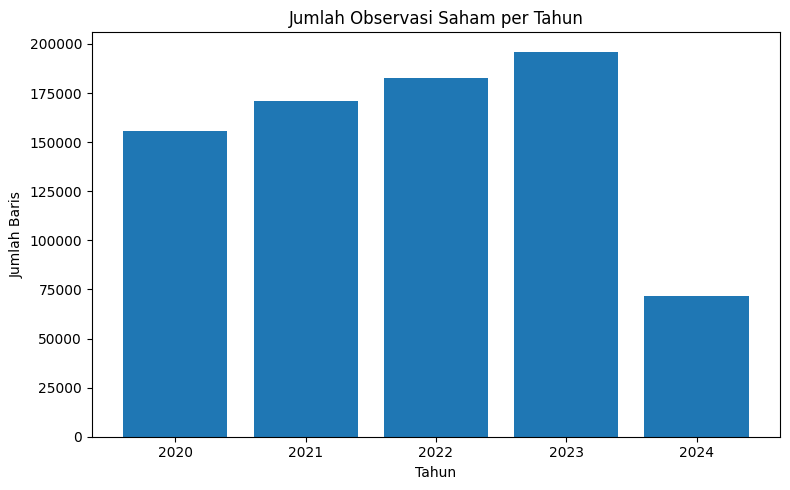

In [8]:
# ============================================================
# Visualisasi jumlah observasi per tahun
# ============================================================

rows_per_year = df.assign(year=df["date"].dt.year).groupby("year").size()

plt.figure(figsize=(8, 5))
plt.bar(rows_per_year.index.astype(str), rows_per_year.values)
plt.title("Jumlah Observasi Saham per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Baris")
plt.tight_layout()
plt.show()


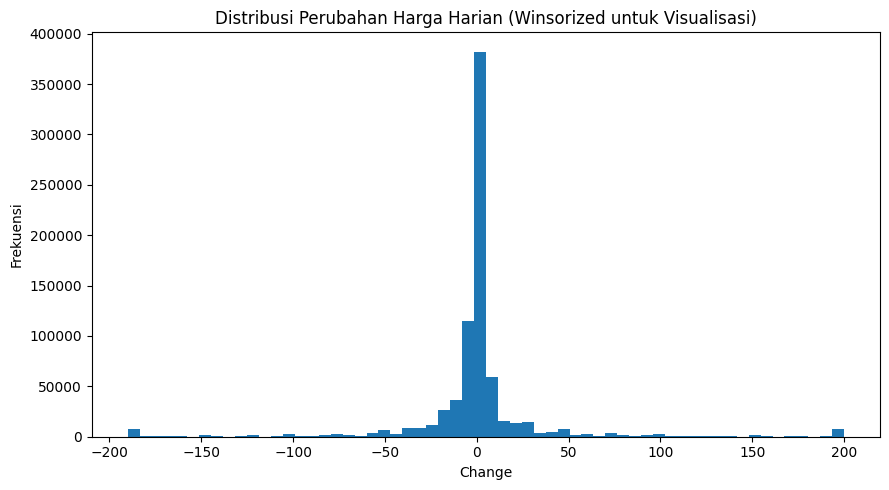

In [9]:
# ============================================================
# Visualisasi distribusi Change
# ============================================================

change_for_plot = df["change"].clip(
    lower=df["change"].quantile(0.01),
    upper=df["change"].quantile(0.99),
)

plt.figure(figsize=(9, 5))
plt.hist(change_for_plot, bins=60)
plt.title("Distribusi Perubahan Harga Harian (Winsorized untuk Visualisasi)")
plt.xlabel("Change")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()


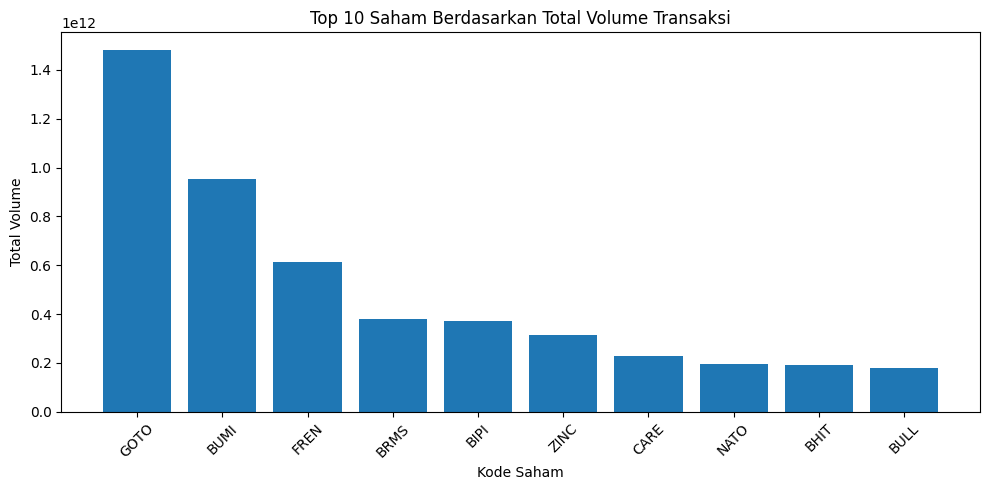

,total_volume
stock_code,
GOTO,"1,479,460,336,400.0000"
BUMI,"955,067,277,800.0000"
FREN,"614,162,172,200.0000"
BRMS,"378,275,242,900.0000"
BIPI,"370,478,025,100.0000"
ZINC,"315,066,068,300.0000"
CARE,"229,280,267,300.0000"
NATO,"197,673,416,100.0000"
BHIT,"192,667,738,600.0000"


In [10]:
# ============================================================
# Top 10 saham berdasarkan total volume transaksi
# ============================================================

top_volume_stocks = (
    df.groupby("stock_code")["volume"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 5))
plt.bar(top_volume_stocks.index, top_volume_stocks.values)
plt.title("Top 10 Saham Berdasarkan Total Volume Transaksi")
plt.xlabel("Kode Saham")
plt.ylabel("Total Volume")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(top_volume_stocks.to_frame("total_volume"))


In [11]:
# ============================================================
# Ringkasan outlier dengan metode IQR
# ============================================================

outlier_columns = [
    "previous",
    "high",
    "low",
    "close",
    "volume",
    "value",
    "frequency",
    "foreign_sell",
    "foreign_buy",
]

outlier_summary = []

for column in outlier_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()

    outlier_summary.append({
        "column": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_ratio": outlier_count / len(df),
    })

outlier_summary_df = pd.DataFrame(outlier_summary).sort_values(
    "outlier_ratio", ascending=False
)

display(outlier_summary_df)


,column,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_ratio
8,foreign_buy,0.0000,"159,400.0000","159,400.0000","-239,100.0000","398,500.0000",160076,0.2060
7,foreign_sell,0.0000,"206,200.0000","206,200.0000","-309,300.0000","515,500.0000",157854,0.2031
5,value,"2,522,000.0000","2,401,939,000.0000","2,399,417,000.0000","-3,596,603,500.0000","6,001,064,500.0000",141155,0.1816
4,volume,"7,000.0000","6,342,400.0000","6,335,400.0000","-9,496,100.0000","15,845,500.0000",125660,0.1617
6,frequency,9.0000,897.0000,888.0000,"-1,323.0000","2,229.0000",116879,0.1504
3,close,104.0000,"1,000.0000",896.0000,"-1,240.0000","2,344.0000",98076,0.1262
0,previous,104.0000,"1,000.0000",896.0000,"-1,240.0000","2,344.0000",98057,0.1262
2,low,66.0000,840.0000,774.0000,"-1,095.0000","2,001.0000",93543,0.1204
1,high,71.0000,880.0000,809.0000,"-1,142.5000","2,093.5000",93411,0.1202


# 3. Data Preparation dan Feature Engineering

Target dibuat menggunakan harga penutupan pada hari perdagangan berikutnya untuk setiap kode saham:

- `target_next_day_up = 1` apabila `next_close > close`
- `target_next_day_up = 0` apabila `next_close <= close`

Hal ini lebih tepat dibandingkan memprediksi perubahan harga pada hari yang sama karena seluruh fitur yang digunakan sudah tersedia pada akhir hari perdagangan saat ini. Pendekatan ini juga mengurangi risiko **target leakage**.

Fitur tambahan yang dibuat meliputi:
- return harian dan lag return;
- perubahan log-volume;
- moving average 5 dan 10 periode;
- volatilitas 5 periode;
- posisi harga terhadap moving average;
- rentang intraday;
- net foreign flow;
- rasio foreign buy;
- hari dan bulan perdagangan.


In [12]:
# ============================================================
# Feature engineering
# ============================================================

df = df.sort_values(["stock_code", "date"]).reset_index(drop=True)
stock_group = df.groupby("stock_code", group_keys=False)

# Return harga
df["return_1d"] = stock_group["close"].pct_change(fill_method=None)
df["return_lag_1"] = stock_group["return_1d"].shift(1)
df["return_lag_2"] = stock_group["return_1d"].shift(2)
df["return_lag_3"] = stock_group["return_1d"].shift(3)

# Transformasi volume, value, frequency
df["volume_log"] = np.log1p(df["volume"])
df["value_log"] = np.log1p(df["value"])
df["frequency_log"] = np.log1p(df["frequency"])
df["volume_log_change_1d"] = stock_group["volume_log"].diff()

# Moving average dan volatilitas
df["close_sma_5"] = stock_group["close"].transform(
    lambda series: series.rolling(5, min_periods=5).mean()
)
df["close_sma_10"] = stock_group["close"].transform(
    lambda series: series.rolling(10, min_periods=10).mean()
)
df["volatility_5"] = stock_group["return_1d"].transform(
    lambda series: series.rolling(5, min_periods=5).std()
)

df["close_to_sma_5"] = df["close"] / df["close_sma_5"] - 1
df["close_to_sma_10"] = df["close"] / df["close_sma_10"] - 1

# Fitur pergerakan harga
df["intraday_range_pct"] = (
    (df["high"] - df["low"]) / df["previous"].replace(0, np.nan)
)
df["daily_change_pct"] = df["change"] / df["previous"].replace(0, np.nan)

# Aktivitas investor asing
foreign_net = df["foreign_buy"] - df["foreign_sell"]
df["foreign_net_signed_log"] = np.sign(foreign_net) * np.log1p(np.abs(foreign_net))
df["foreign_buy_ratio"] = (
    df["foreign_buy"] / (df["foreign_buy"] + df["foreign_sell"] + 1)
)

# Fitur kalender
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

# Target hari perdagangan berikutnya
df["next_close"] = stock_group["close"].shift(-1)
df["target_next_day_up"] = np.where(
    df["next_close"].isna(),
    np.nan,
    (df["next_close"] > df["close"]).astype(int),
)

FEATURES = [
    "previous",
    "close",
    "high",
    "low",
    "volume_log",
    "value_log",
    "frequency_log",
    "foreign_net_signed_log",
    "foreign_buy_ratio",
    "return_1d",
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "volume_log_change_1d",
    "intraday_range_pct",
    "daily_change_pct",
    "close_to_sma_5",
    "close_to_sma_10",
    "volatility_5",
    "day_of_week",
    "month",
]

print("Jumlah fitur:", len(FEATURES))
print(FEATURES)


Jumlah fitur: 21
['previous', 'close', 'high', 'low', 'volume_log', 'value_log', 'frequency_log', 'foreign_net_signed_log', 'foreign_buy_ratio', 'return_1d', 'return_lag_1', 'return_lag_2', 'return_lag_3', 'volume_log_change_1d', 'intraday_range_pct', 'daily_change_pct', 'close_to_sma_5', 'close_to_sma_10', 'volatility_5', 'day_of_week', 'month']


In [13]:
# ============================================================
# Menyiapkan dataset modelling dan dataset deployment
# ============================================================

feature_ready_df = (
    df[["date", "stock_code", "company_name"] + FEATURES]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

model_df = (
    df[["date", "stock_code", "company_name", "target_next_day_up"] + FEATURES]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

model_df["target_next_day_up"] = model_df["target_next_day_up"].astype(int)

print("Ukuran dataset modelling :", model_df.shape)
print("Ukuran data deployment   :", feature_ready_df.shape)
print("Tanggal modelling        :", model_df["date"].min().date(), "sampai", model_df["date"].max().date())

display(model_df.head())


Ukuran dataset modelling : (767838, 25)
Ukuran data deployment   : (768774, 24)
Tanggal modelling        : 2020-01-15 sampai 2024-05-15


,date,stock_code,company_name,target_next_day_up,previous,close,high,low,volume_log,value_log,frequency_log,foreign_net_signed_log,foreign_buy_ratio,return_1d,return_lag_1,return_lag_2,return_lag_3,volume_log_change_1d,intraday_range_pct,daily_change_pct,close_to_sma_5,close_to_sma_10,volatility_5,day_of_week,month
9,2020-01-15,AALI,Astra Agro Lestari Tbk.,1,"13,200.0000","12,525.0000","13,200.0000","12,525.0000",14.5722,24.0277,7.9077,-12.7302,0.2951,-0.0511,-0.0365,0.0018,-0.0126,0.2723,0.0511,-0.0511,-0.0646,-0.0743,0.0352,2,1
10,2020-01-16,AALI,Astra Agro Lestari Tbk.,1,"12,525.0000","12,675.0000","12,950.0000","12,525.0000",14.1443,23.5989,7.3454,11.8685,0.6446,0.0120,-0.0511,-0.0365,0.0018,-0.4279,0.0339,0.0120,-0.0365,-0.0538,0.0263,3,1
11,2020-01-17,AALI,Astra Agro Lestari Tbk.,0,"12,675.0000","12,875.0000","12,925.0000","12,650.0000",13.4810,22.9414,6.6039,9.7172,0.5326,0.0158,0.0120,-0.0511,-0.0365,-0.6633,0.0217,0.0158,-0.0092,-0.0299,0.0303,4,1
12,2020-01-20,AALI,Astra Agro Lestari Tbk.,0,"12,875.0000","12,600.0000","13,000.0000","12,500.0000",14.2051,23.6471,7.3363,8.0712,0.5140,-0.0214,0.0158,0.0120,-0.0511,0.7241,0.0388,-0.0214,-0.0137,-0.0442,0.0295,0,1
13,2020-01-22,AALI,Astra Agro Lestari Tbk.,0,"12,350.0000","12,425.0000","12,500.0000","12,150.0000",13.7821,23.2005,6.8607,12.4159,0.9135,-0.0139,-0.0214,0.0158,0.0120,-0.4231,0.0283,0.0061,-0.0155,-0.0504,0.0272,2,1


,count,ratio
target,,
0,542506,0.7065
1,225332,0.2935


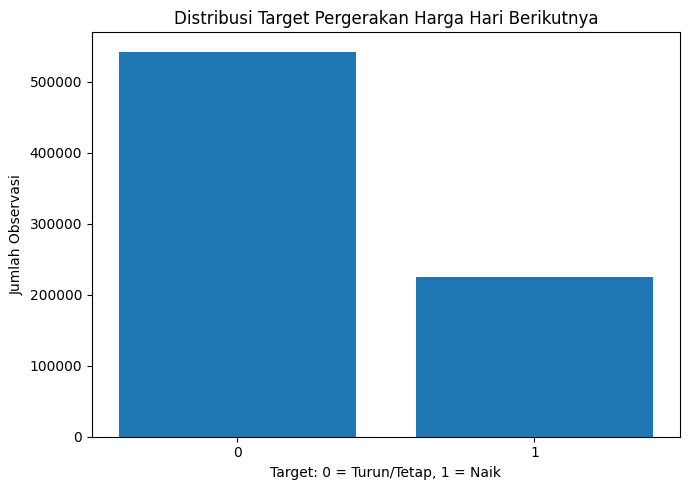

In [14]:
# ============================================================
# Distribusi target
# ============================================================

target_distribution = (
    model_df["target_next_day_up"]
    .value_counts()
    .rename_axis("target")
    .to_frame("count")
)
target_distribution["ratio"] = target_distribution["count"] / target_distribution["count"].sum()

display(target_distribution)

plt.figure(figsize=(7, 5))
plt.bar(target_distribution.index.astype(str), target_distribution["count"])
plt.title("Distribusi Target Pergerakan Harga Hari Berikutnya")
plt.xlabel("Target: 0 = Turun/Tetap, 1 = Naik")
plt.ylabel("Jumlah Observasi")
plt.tight_layout()
plt.show()


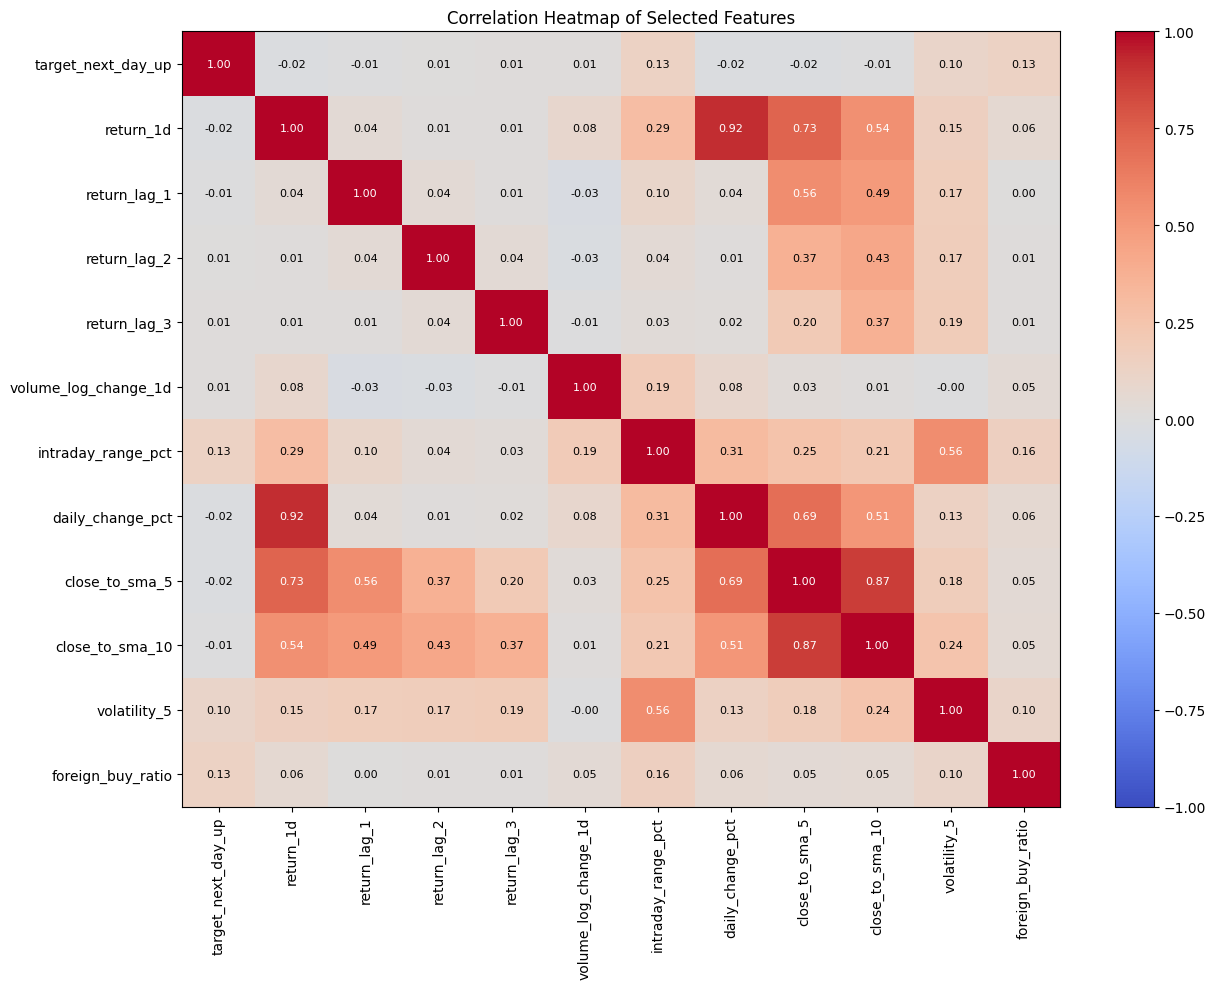

,target_next_day_up,return_1d,return_lag_1,return_lag_2,return_lag_3,volume_log_change_1d,intraday_range_pct,daily_change_pct,close_to_sma_5,close_to_sma_10,volatility_5,foreign_buy_ratio
target_next_day_up,1.0000,-0.0230,-0.0066,0.0076,0.0099,0.0125,0.1298,-0.0230,-0.0184,-0.0055,0.1044,0.1297
return_1d,-0.0230,1.0000,0.0391,0.0140,0.0139,0.0785,0.2921,0.9207,0.7279,0.5435,0.1530,0.0570
return_lag_1,-0.0066,0.0391,1.0000,0.0392,0.0139,-0.0316,0.0985,0.0384,0.5578,0.4931,0.1650,0.0024
return_lag_2,0.0076,0.0140,0.0392,1.0000,0.0398,-0.0293,0.0393,0.0146,0.3748,0.4290,0.1726,0.0111
return_lag_3,0.0099,0.0139,0.0139,0.0398,1.0000,-0.0057,0.0307,0.0156,0.1992,0.3674,0.1855,0.0130
volume_log_change_1d,0.0125,0.0785,-0.0316,-0.0293,-0.0057,1.0000,0.1879,0.0828,0.0298,0.0122,-0.0013,0.0464
intraday_range_pct,0.1298,0.2921,0.0985,0.0393,0.0307,0.1879,1.0000,0.3124,0.2517,0.2125,0.5568,0.1560
daily_change_pct,-0.0230,0.9207,0.0384,0.0146,0.0156,0.0828,0.3124,1.0000,0.6922,0.5145,0.1345,0.0621
close_to_sma_5,-0.0184,0.7279,0.5578,0.3748,0.1992,0.0298,0.2517,0.6922,1.0000,0.8702,0.1796,0.0465
close_to_sma_10,-0.0055,0.5435,0.4931,0.4290,0.3674,0.0122,0.2125,0.5145,0.8702,1.0000,0.2432,0.0469


In [33]:
# ============================================================
# Korelasi fitur numerik
# ============================================================

correlation_columns = [
    "target_next_day_up",
    "return_1d",
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "volume_log_change_1d",
    "intraday_range_pct",
    "daily_change_pct",
    "close_to_sma_5",
    "close_to_sma_10",
    "volatility_5",
    "foreign_buy_ratio",
]

correlation_matrix = model_df[correlation_columns].corr()

plt.figure(figsize=(13, 10))

heatmap = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",   # Biru = negatif, putih = mendekati 0, merah = positif
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(heatmap)

plt.xticks(
    ticks=np.arange(len(correlation_columns)),
    labels=correlation_columns,
    rotation=90
)

plt.yticks(
    ticks=np.arange(len(correlation_columns)),
    labels=correlation_columns
)

# Menampilkan angka korelasi di setiap kotak
for row in range(len(correlation_columns)):
    for column in range(len(correlation_columns)):
        value = correlation_matrix.iloc[row, column]

        # Warna tulisan agar tetap terbaca
        text_color = "white" if abs(value) >= 0.50 else "black"

        plt.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=8
        )

plt.title("Correlation Heatmap of Selected Features")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(4))

## Pembagian Data Secara Kronologis

Dataset tidak diacak secara langsung karena data saham memiliki urutan waktu. Data dibagi berdasarkan tanggal perdagangan unik:

- 70% tanggal awal untuk training;
- 15% tanggal berikutnya untuk validation;
- 15% tanggal paling akhir untuk testing.

Validation digunakan untuk membandingkan model dan menentukan threshold. Test digunakan satu kali untuk mengevaluasi performa akhir model terbaik.


In [16]:
# ============================================================
# Split data secara kronologis: train, validation, test
# ============================================================

unique_dates = np.array(sorted(model_df["date"].unique()))

train_end_date = unique_dates[int(len(unique_dates) * 0.70)]
validation_end_date = unique_dates[int(len(unique_dates) * 0.85)]

train_df = model_df[model_df["date"] < train_end_date].copy()
validation_df = model_df[
    (model_df["date"] >= train_end_date)
    & (model_df["date"] < validation_end_date)
].copy()
test_df = model_df[model_df["date"] >= validation_end_date].copy()

split_summary = pd.DataFrame([
    {
        "dataset": "Train",
        "start_date": train_df["date"].min(),
        "end_date": train_df["date"].max(),
        "rows": len(train_df),
        "positive_ratio": train_df["target_next_day_up"].mean(),
    },
    {
        "dataset": "Validation",
        "start_date": validation_df["date"].min(),
        "end_date": validation_df["date"].max(),
        "rows": len(validation_df),
        "positive_ratio": validation_df["target_next_day_up"].mean(),
    },
    {
        "dataset": "Test",
        "start_date": test_df["date"].min(),
        "end_date": test_df["date"].max(),
        "rows": len(test_df),
        "positive_ratio": test_df["target_next_day_up"].mean(),
    },
])

display(split_summary)

print("Batas akhir train      :", pd.Timestamp(train_end_date).date())
print("Batas akhir validation :", pd.Timestamp(validation_end_date).date())


,dataset,start_date,end_date,rows,positive_ratio
0,Train,2020-01-15,2023-01-11,508355,0.2969
1,Validation,2023-01-12,2023-09-15,125827,0.2955
2,Test,2023-09-18,2024-05-15,133656,0.2786


Batas akhir train      : 2023-01-12
Batas akhir validation : 2023-09-18


## Penanganan Nilai Ekstrem Tanpa Data Leakage

Nilai ekstrem pada fitur persentase ditangani dengan clipping pada persentil 0,1% dan 99,9%. Batas clipping dihitung hanya dari data training, lalu diterapkan ke validation dan test. Dengan demikian, informasi masa depan tidak digunakan saat menyiapkan data training.


In [17]:
# ============================================================
# Clipping fitur ekstrem berdasarkan distribusi data training
# ============================================================

CLIP_COLUMNS = [
    "return_1d",
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "volume_log_change_1d",
    "intraday_range_pct",
    "daily_change_pct",
    "close_to_sma_5",
    "close_to_sma_10",
    "volatility_5",
]

clip_bounds = {}

for column in CLIP_COLUMNS:
    lower_bound, upper_bound = train_df[column].quantile([0.001, 0.999])
    clip_bounds[column] = (float(lower_bound), float(upper_bound))

    train_df[column] = train_df[column].clip(lower_bound, upper_bound)
    validation_df[column] = validation_df[column].clip(lower_bound, upper_bound)
    test_df[column] = test_df[column].clip(lower_bound, upper_bound)

clip_bounds_df = pd.DataFrame(
    [
        {"column": column, "lower_bound": bounds[0], "upper_bound": bounds[1]}
        for column, bounds in clip_bounds.items()
    ]
)

display(clip_bounds_df)


,column,lower_bound,upper_bound
0,return_1d,-0.1387,0.3433
1,return_lag_1,-0.1396,0.3433
2,return_lag_2,-0.1400,0.3433
3,return_lag_3,-0.1416,0.3433
4,volume_log_change_1d,-12.0907,12.5054
5,intraday_range_pct,0.0000,0.3656
6,daily_change_pct,-0.1147,0.3403
7,close_to_sma_5,-0.1851,0.3730
8,close_to_sma_10,-0.3168,0.6248
9,volatility_5,0.0000,0.2239


# 4. Modelling

Model yang dibandingkan:

1. **Dummy Baseline** sebagai acuan minimum.
2. **Logistic Regression** sebagai model linear baseline.
3. **Decision Tree** untuk menangani pola non-linear secara sederhana.
4. **Random Forest A** sebagai ensemble tree dengan konfigurasi awal.
5. **Random Forest B** sebagai improvement dengan jumlah pohon dan kedalaman yang lebih besar.

Karena dataset sangat besar, model machine learning dilatih menggunakan sampel training yang diseimbangkan agar runtime tetap efisien. Random Forest menggunakan sampel yang lebih kecil karena komputasinya lebih berat. Seluruh validation dan test tetap digunakan secara utuh.


In [18]:
# ============================================================
# Fungsi sampling seimbang untuk Random Forest
# ============================================================

def make_balanced_sample(dataframe, target_column, max_rows, random_state=42):
    # Mengambil sampel kelas 0 dan 1 dengan jumlah seimbang.
    per_class = max_rows // 2

    class_0 = dataframe[dataframe[target_column] == 0]
    class_1 = dataframe[dataframe[target_column] == 1]

    sample_0 = class_0.sample(
        n=min(per_class, len(class_0)),
        random_state=random_state,
    )
    sample_1 = class_1.sample(
        n=min(per_class, len(class_1)),
        random_state=random_state,
    )

    return (
        pd.concat([sample_0, sample_1], ignore_index=True)
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )


balanced_train_df = make_balanced_sample(
    dataframe=train_df,
    target_column="target_next_day_up",
    max_rows=GENERAL_SAMPLE_ROWS,
    random_state=RANDOM_STATE,
)

rf_train_df = make_balanced_sample(
    dataframe=train_df,
    target_column="target_next_day_up",
    max_rows=RF_SAMPLE_ROWS,
    random_state=RANDOM_STATE,
)

print("Ukuran training penuh         :", len(train_df))
print("Ukuran training model umum    :", len(balanced_train_df))
print("Ukuran training Random Forest :", len(rf_train_df))
print("\nDistribusi kelas sampel model umum:")
display(balanced_train_df["target_next_day_up"].value_counts().to_frame("count"))
print("Distribusi kelas sampel Random Forest:")
display(rf_train_df["target_next_day_up"].value_counts().to_frame("count"))


Ukuran training penuh         : 508355
Ukuran training model umum    : 40000
Ukuran training Random Forest : 30000

Distribusi kelas sampel model umum:


,count
target_next_day_up,
1,20000
0,20000


Distribusi kelas sampel Random Forest:


,count
target_next_day_up,
0,15000
1,15000


In [19]:
# ============================================================
# Menyiapkan X dan y
# ============================================================

X_train = train_df[FEATURES]
y_train = train_df["target_next_day_up"]

X_balanced_train = balanced_train_df[FEATURES]
y_balanced_train = balanced_train_df["target_next_day_up"]

X_validation = validation_df[FEATURES]
y_validation = validation_df["target_next_day_up"]

X_test = test_df[FEATURES]
y_test = test_df["target_next_day_up"]

X_rf_train = rf_train_df[FEATURES]
y_rf_train = rf_train_df["target_next_day_up"]

print("X_train penuh       :", X_train.shape)
print("X_balanced_train    :", X_balanced_train.shape)
print("X_validation        :", X_validation.shape)
print("X_test       :", X_test.shape)
print("X_rf_train   :", X_rf_train.shape)


X_train penuh       : (508355, 21)
X_balanced_train    : (40000, 21)
X_validation        : (125827, 21)
X_test       : (133656, 21)
X_rf_train   : (30000, 21)


In [20]:
# ============================================================
# Inisialisasi model
# ============================================================

model_registry = {
    "Dummy Baseline": {
        "model": DummyClassifier(strategy="most_frequent"),
        "X_train": X_train,
        "y_train": y_train,
    },
    "Logistic Regression": {
        "model": Pipeline([
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    max_iter=400,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]),
        "X_train": X_balanced_train,
        "y_train": y_balanced_train,
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(
            max_depth=10,
            min_samples_leaf=30,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "X_train": X_balanced_train,
        "y_train": y_balanced_train,
    },
    "Random Forest A": {
        "model": RandomForestClassifier(
            n_estimators=30,
            max_depth=8,
            min_samples_leaf=20,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=2,
            random_state=RANDOM_STATE,
        ),
        "X_train": X_rf_train,
        "y_train": y_rf_train,
    },
    "Random Forest B": {
        "model": RandomForestClassifier(
            n_estimators=50,
            max_depth=10,
            min_samples_leaf=15,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=2,
            random_state=RANDOM_STATE,
        ),
        "X_train": X_rf_train,
        "y_train": y_rf_train,
    },
}

print("Model yang akan dibandingkan:")
for model_name in model_registry:
    print("-", model_name)


Model yang akan dibandingkan:
- Dummy Baseline
- Logistic Regression
- Decision Tree
- Random Forest A
- Random Forest B


In [21]:
# ============================================================
# Fungsi evaluasi model
# ============================================================

def get_prediction_probability(model, X):
    # Mengambil probabilitas kelas positif.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]

    return model.predict(X).astype(float)


def calculate_classification_metrics(y_true, probabilities, threshold=0.50):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1_score": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
    }


In [34]:
# ============================================================
# Training dan evaluasi pada validation set
# ============================================================

import time

validation_results = []

for model_name, model_info in model_registry.items():
    print(f"Training: {model_name}")

    model = model_info["model"]
    start_time = time.time()

    model.fit(
        model_info["X_train"],
        model_info["y_train"],
    )

    training_seconds = time.time() - start_time
    validation_probability = get_prediction_probability(model, X_validation)

    metrics = calculate_classification_metrics(
        y_true=y_validation,
        probabilities=validation_probability,
        threshold=0.50,
    )

    metrics["model"] = model_name
    metrics["training_seconds"] = training_seconds
    validation_results.append(metrics)

    print(
        f"  ROC-AUC: {metrics['roc_auc']:.4f} | "
        f"Balanced Accuracy: {metrics['balanced_accuracy']:.4f} | "
        f"F1: {metrics['f1_score']:.4f} | "
        f"Training time: {training_seconds:.2f} detik"
    )

validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(validation_results_df)


Training: Dummy Baseline
  ROC-AUC: 0.5000 | Balanced Accuracy: 0.5000 | F1: 0.0000 | Training time: 0.03 detik
Training: Logistic Regression
  ROC-AUC: 0.6675 | Balanced Accuracy: 0.6172 | F1: 0.4972 | Training time: 1.39 detik
Training: Decision Tree
  ROC-AUC: 0.6741 | Balanced Accuracy: 0.6368 | F1: 0.5254 | Training time: 2.05 detik
Training: Random Forest A
  ROC-AUC: 0.6981 | Balanced Accuracy: 0.6488 | F1: 0.5393 | Training time: 4.80 detik
Training: Random Forest B
  ROC-AUC: 0.6971 | Balanced Accuracy: 0.6490 | F1: 0.5382 | Training time: 3.96 detik


,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc,model,training_seconds
0,0.5482,0.6488,0.3859,0.8947,0.5393,0.6981,Random Forest A,4.7978
1,0.5581,0.6490,0.3893,0.8714,0.5382,0.6971,Random Forest B,3.9601
2,0.5610,0.6368,0.3860,0.8222,0.5254,0.6741,Decision Tree,2.0540
3,0.5870,0.6172,0.3883,0.6909,0.4972,0.6675,Logistic Regression,1.3894
4,0.7045,0.5000,0.0000,0.0000,0.0000,0.5000,Dummy Baseline,0.0349


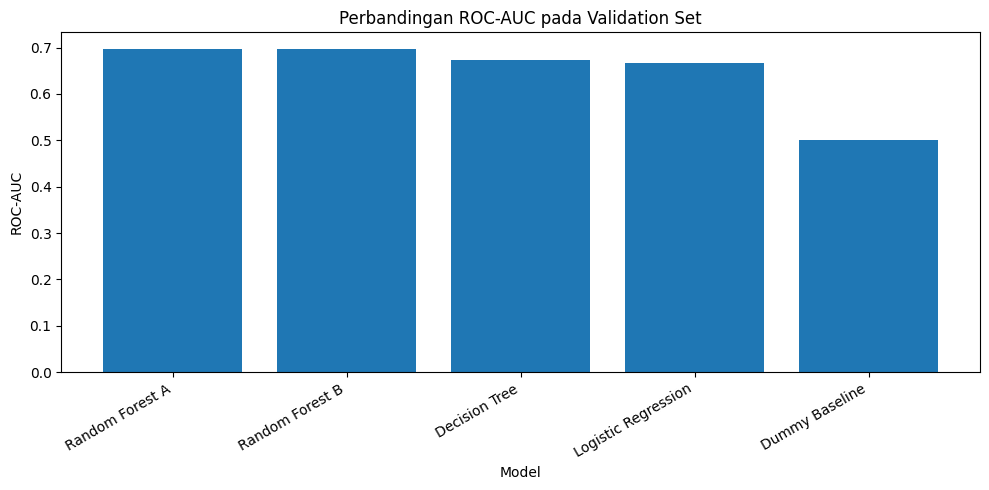

In [35]:
# ============================================================
# Visualisasi perbandingan ROC-AUC validation
# ============================================================

plt.figure(figsize=(10, 5))
plt.bar(
    validation_results_df["model"],
    validation_results_df["roc_auc"],
)
plt.title("Perbandingan ROC-AUC pada Validation Set")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# 5. Evaluation

Model terbaik dipilih berdasarkan **ROC-AUC validation**. ROC-AUC digunakan karena target tidak seimbang dan model perlu dinilai dari kemampuan membedakan kelas naik dan turun/tetap, bukan hanya accuracy.

Threshold klasifikasi diseleksi menggunakan validation set berdasarkan balanced accuracy. Setelah threshold dipilih, evaluasi akhir dilakukan pada test set.


In [36]:
# ============================================================
# Memilih model terbaik berdasarkan ROC-AUC validation
# ============================================================

best_model_name = validation_results_df.iloc[0]["model"]
best_model = model_registry[best_model_name]["model"]

print("Model terbaik berdasarkan ROC-AUC validation:", best_model_name)


Model terbaik berdasarkan ROC-AUC validation: Random Forest A


In [25]:
# ============================================================
# Threshold tuning menggunakan validation set
# ============================================================

validation_probability_best = get_prediction_probability(
    best_model,
    X_validation,
)

threshold_candidates = np.arange(0.30, 0.71, 0.01)
threshold_rows = []

for threshold in threshold_candidates:
    metrics = calculate_classification_metrics(
        y_true=y_validation,
        probabilities=validation_probability_best,
        threshold=float(threshold),
    )

    threshold_rows.append({
        "threshold": float(threshold),
        **metrics,
    })

threshold_results_df = pd.DataFrame(threshold_rows)

best_threshold_row = threshold_results_df.sort_values(
    ["balanced_accuracy", "f1_score", "roc_auc"],
    ascending=False,
).iloc[0]

best_threshold = float(best_threshold_row["threshold"])

print("Threshold terbaik:", round(best_threshold, 4))
display(threshold_results_df.sort_values("balanced_accuracy", ascending=False).head(10))


Threshold terbaik: 0.52


,threshold,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc
22,0.5200,0.5712,0.6499,0.3944,0.8424,0.5372,0.6981
21,0.5100,0.5595,0.6499,0.3901,0.8708,0.5388,0.6981
23,0.5300,0.5833,0.6490,0.3990,0.8096,0.5345,0.6981
20,0.5000,0.5482,0.6488,0.3859,0.8947,0.5393,0.6981
19,0.4900,0.5386,0.6477,0.3826,0.9144,0.5394,0.6981
24,0.5400,0.5954,0.6471,0.4037,0.7735,0.5305,0.6981
18,0.4800,0.5297,0.6456,0.3793,0.9291,0.5387,0.6981
17,0.4700,0.5227,0.6445,0.3770,0.9426,0.5385,0.6981
25,0.5500,0.6073,0.6432,0.4082,0.7310,0.5238,0.6981
16,0.4600,0.5163,0.6427,0.3747,0.9517,0.5377,0.6981


In [26]:
# ============================================================
# Evaluasi akhir pada test set
# ============================================================

test_probability = get_prediction_probability(best_model, X_test)
test_predictions = (test_probability >= best_threshold).astype(int)

test_metrics = calculate_classification_metrics(
    y_true=y_test,
    probabilities=test_probability,
    threshold=best_threshold,
)

test_metrics_df = pd.DataFrame(
    [{"metric": metric, "value": value} for metric, value in test_metrics.items()]
)

print("Model terbaik  :", best_model_name)
print("Threshold      :", round(best_threshold, 4))
display(test_metrics_df)

print("\nClassification Report:")
print(classification_report(y_test, test_predictions, digits=4))


Model terbaik  : Random Forest A
Threshold      : 0.52


,metric,value
0,accuracy,0.5800
1,balanced_accuracy,0.6544
2,precision,0.3821
3,recall,0.8225
4,f1_score,0.5218
5,roc_auc,0.7070



Classification Report:
              precision    recall  f1-score   support

           0     0.8765    0.4863    0.6256     96424
           1     0.3821    0.8225    0.5218     37232

    accuracy                         0.5800    133656
   macro avg     0.6293    0.6544    0.5737    133656
weighted avg     0.7388    0.5800    0.5967    133656



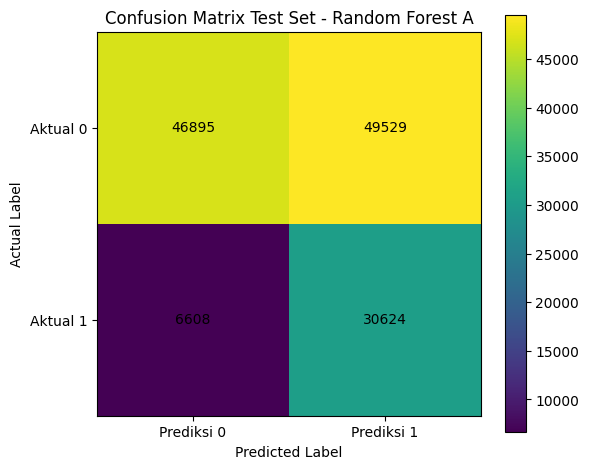

,Predicted 0,Predicted 1
Actual 0,46895,49529
Actual 1,6608,30624


In [27]:
# ============================================================
# Confusion matrix test set
# ============================================================

test_confusion_matrix = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 5))
plt.imshow(test_confusion_matrix)
plt.colorbar()

for row in range(test_confusion_matrix.shape[0]):
    for column in range(test_confusion_matrix.shape[1]):
        plt.text(
            column,
            row,
            str(test_confusion_matrix[row, column]),
            ha="center",
            va="center",
        )

plt.xticks([0, 1], ["Prediksi 0", "Prediksi 1"])
plt.yticks([0, 1], ["Aktual 0", "Aktual 1"])
plt.title(f"Confusion Matrix Test Set - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(
        test_confusion_matrix,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"],
    )
)


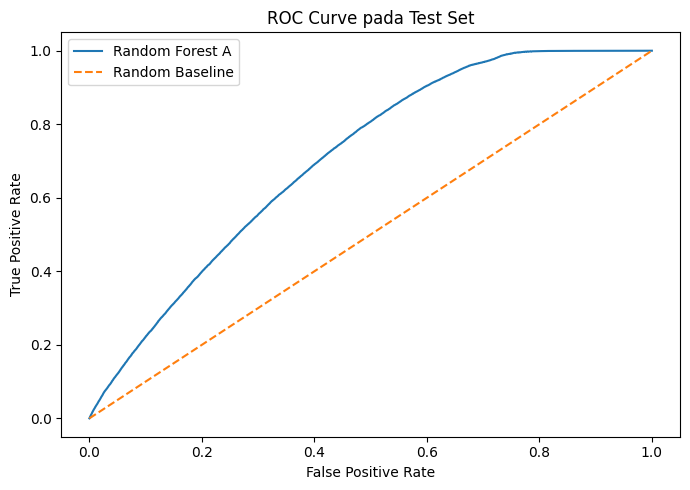

Test ROC-AUC: 0.707


In [28]:
# ============================================================
# ROC curve test set
# ============================================================

false_positive_rate, true_positive_rate, _ = roc_curve(
    y_test,
    test_probability,
)

plt.figure(figsize=(7, 5))
plt.plot(false_positive_rate, true_positive_rate, label=f"{best_model_name}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Baseline")
plt.title("ROC Curve pada Test Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

print("Test ROC-AUC:", round(test_metrics["roc_auc"], 4))


,feature,importance
0,volatility_5,0.1754
1,low,0.1725
2,value_log,0.1165
3,high,0.1006
4,intraday_range_pct,0.0938
5,frequency_log,0.0529
6,close_to_sma_5,0.0456
7,volume_log,0.0408
8,previous,0.0381
9,close_to_sma_10,0.0350


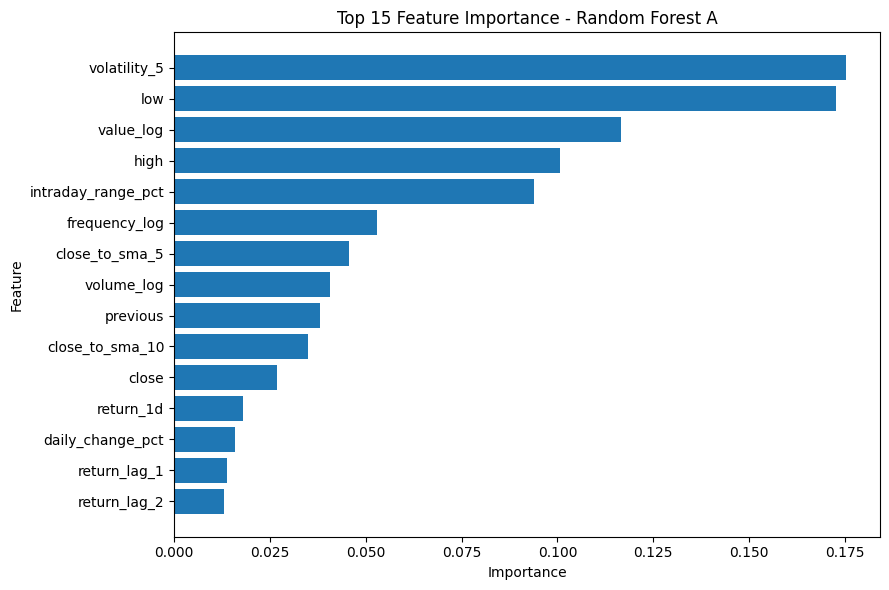

In [29]:
# ============================================================
# Feature importance
# ============================================================

if hasattr(best_model, "feature_importances_"):
    feature_importance_df = (
        pd.DataFrame({
            "feature": FEATURES,
            "importance": best_model.feature_importances_,
        })
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

elif hasattr(best_model, "named_steps") and hasattr(
    best_model.named_steps["model"],
    "coef_",
):
    feature_importance_df = (
        pd.DataFrame({
            "feature": FEATURES,
            "importance": np.abs(best_model.named_steps["model"].coef_[0]),
        })
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

else:
    feature_importance_df = pd.DataFrame({
        "feature": FEATURES,
        "importance": np.nan,
    })

display(feature_importance_df.head(15))

top_feature_importance = feature_importance_df.head(15).sort_values(
    "importance",
    ascending=True,
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_feature_importance["feature"],
    top_feature_importance["importance"],
)
plt.title(f"Top 15 Feature Importance - {best_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## Interpretasi Evaluasi

Perhatikan hal-hal berikut saat menulis laporan:

1. **Accuracy tidak boleh digunakan sendirian** karena kelas target tidak seimbang.
2. **Balanced accuracy** menunjukkan performa rata-rata terhadap kelas naik dan kelas turun/tetap.
3. **Recall kelas naik** penting apabila tujuan analisis adalah menangkap sebanyak mungkin peluang kenaikan.
4. **ROC-AUC** dipakai sebagai metrik utama untuk membandingkan kemampuan pemisahan kelas.
5. Confusion matrix membantu melihat jumlah prediksi benar dan salah secara rinci.
6. Feature importance menjelaskan indikator perdagangan yang paling berpengaruh terhadap keputusan model.

Hasil model perlu dibaca sebagai sinyal statistik berdasarkan data historis, bukan sebagai kepastian pergerakan pasar.


# 6. Deployment Sederhana

Tahap deployment dilakukan dengan:
1. menyimpan model terbaik;
2. menyimpan daftar fitur, batas clipping, threshold, dan metrik test;
3. membuat fungsi untuk menghasilkan probabilitas kenaikan pada hari perdagangan berikutnya dari observasi terbaru suatu kode saham.


In [30]:
# ============================================================
# Menyimpan model dan metadata deployment
# ============================================================

deployment_artifact = {
    "model": best_model,
    "best_model_name": best_model_name,
    "features": FEATURES,
    "clip_bounds": clip_bounds,
    "threshold": best_threshold,
    "test_metrics": test_metrics,
    "target_definition": "1 jika close hari perdagangan berikutnya > close saat ini, selainnya 0",
}

MODEL_OUTPUT_PATH = "idx_next_day_direction_model.joblib"
METADATA_OUTPUT_PATH = "idx_next_day_direction_metadata.json"

joblib.dump(deployment_artifact, MODEL_OUTPUT_PATH)

metadata_for_json = {
    "best_model_name": best_model_name,
    "features": FEATURES,
    "clip_bounds": clip_bounds,
    "threshold": best_threshold,
    "test_metrics": test_metrics,
    "target_definition": deployment_artifact["target_definition"],
}

with open(METADATA_OUTPUT_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata_for_json, file, indent=2)

print("Model disimpan   :", MODEL_OUTPUT_PATH)
print("Metadata disimpan:", METADATA_OUTPUT_PATH)


Model disimpan   : idx_next_day_direction_model.joblib
Metadata disimpan: idx_next_day_direction_metadata.json


In [31]:
# ============================================================
# Fungsi simulasi prediksi saham terbaru
# ============================================================

def predict_latest_stock_signal(
    stock_code,
    feature_dataframe,
    model,
    features,
    clipping_bounds,
    threshold,
):
    # Prediksi arah harga berikutnya dari observasi terbaru satu saham.
    stock_code = str(stock_code).upper().strip()

    latest_row = (
        feature_dataframe[feature_dataframe["stock_code"] == stock_code]
        .sort_values("date")
        .tail(1)
        .copy()
    )

    if latest_row.empty:
        raise ValueError(f"Kode saham '{stock_code}' tidak ditemukan.")

    for column, (lower_bound, upper_bound) in clipping_bounds.items():
        latest_row[column] = latest_row[column].clip(lower_bound, upper_bound)

    probability_up = float(
        get_prediction_probability(
            model,
            latest_row[features],
        )[0]
    )

    prediction = int(probability_up >= threshold)

    return pd.DataFrame([{
        "stock_code": stock_code,
        "company_name": latest_row["company_name"].iloc[0],
        "latest_date": latest_row["date"].iloc[0],
        "probability_next_day_up": probability_up,
        "threshold": threshold,
        "predicted_class": prediction,
        "interpretation": (
            "Diprediksi naik"
            if prediction == 1
            else "Diprediksi turun atau tetap"
        ),
    }])


# Contoh simulasi: gunakan AALI apabila tersedia.
example_stock_code = (
    "AALI"
    if "AALI" in set(feature_ready_df["stock_code"])
    else feature_ready_df["stock_code"].iloc[0]
)

prediction_example = predict_latest_stock_signal(
    stock_code=example_stock_code,
    feature_dataframe=feature_ready_df,
    model=best_model,
    features=FEATURES,
    clipping_bounds=clip_bounds,
    threshold=best_threshold,
)

display(prediction_example)


,stock_code,company_name,latest_date,probability_next_day_up,threshold,predicted_class,interpretation
0,AALI,Astra Agro Lestari Tbk.,2024-05-16,0.6114,0.5200,1,Diprediksi naik


In [32]:
# ============================================================
# Contoh sinyal untuk beberapa saham dengan data terbaru
# ============================================================

latest_available_date = feature_ready_df["date"].max()

latest_stock_codes = (
    feature_ready_df[feature_ready_df["date"] == latest_available_date]["stock_code"]
    .drop_duplicates()
    .sort_values()
    .head(10)
    .tolist()
)

latest_signals = pd.concat(
    [
        predict_latest_stock_signal(
            stock_code=stock_code,
            feature_dataframe=feature_ready_df,
            model=best_model,
            features=FEATURES,
            clipping_bounds=clip_bounds,
            threshold=best_threshold,
        )
        for stock_code in latest_stock_codes
    ],
    ignore_index=True,
)

display(latest_signals)

SIGNAL_OUTPUT_PATH = "idx_latest_stock_signals_example.csv"
latest_signals.to_csv(SIGNAL_OUTPUT_PATH, index=False)

print("Contoh sinyal disimpan:", SIGNAL_OUTPUT_PATH)


,stock_code,company_name,latest_date,probability_next_day_up,threshold,predicted_class,interpretation
0,AALI,Astra Agro Lestari Tbk.,2024-05-16,0.6114,0.5200,1,Diprediksi naik
1,ABBA,Mahaka Media Tbk.,2024-05-16,0.3711,0.5200,0,Diprediksi turun atau tetap
2,ABDA,Asuransi Bina Dana Arta Tbk.,2024-05-16,0.0408,0.5200,0,Diprediksi turun atau tetap
3,ABMM,ABM Investama Tbk.,2024-05-16,0.6319,0.5200,1,Diprediksi naik
4,ACES,Ace Hardware Indonesia Tbk.,2024-05-16,0.6174,0.5200,1,Diprediksi naik
5,ACRO,Samcro Hyosung Adilestari Tbk.,2024-05-16,0.5336,0.5200,1,Diprediksi naik
6,ACST,Acset Indonusa Tbk.,2024-05-16,0.5551,0.5200,1,Diprediksi naik
7,ADCP,Adhi Commuter Properti Tbk.,2024-05-16,0.0068,0.5200,0,Diprediksi turun atau tetap
8,ADES,Akasha Wira International Tbk.,2024-05-16,0.5943,0.5200,1,Diprediksi naik
9,ADHI,Adhi Karya (Persero) Tbk.,2024-05-16,0.5745,0.5200,1,Diprediksi naik


Contoh sinyal disimpan: idx_latest_stock_signals_example.csv


# 7. Kesimpulan dan Saran

## Kesimpulan
1. Dataset saham IDX berhasil diproses menggunakan tahapan CRISP-DM secara lengkap.
2. Duplikasi data dihapus dan kolom tanggal distandardisasi.
3. Target modelling dirancang sebagai arah pergerakan harga pada hari perdagangan berikutnya agar prediksi lebih realistis dan mengurangi target leakage.
4. Feature engineering mencakup return, lag return, volume, nilai transaksi, frekuensi transaksi, moving average, volatilitas, rentang intraday, serta aktivitas investor asing.
5. Pembagian data dilakukan secara kronologis sehingga evaluasi lebih mencerminkan penggunaan model pada data masa depan.
6. Dummy Baseline, Logistic Regression, Decision Tree, dan dua konfigurasi Random Forest dibandingkan secara sistematis.
7. Model terbaik dipilih berdasarkan ROC-AUC validation dan dievaluasi satu kali menggunakan test set.
8. Model dan metadata deployment disimpan agar dapat digunakan kembali.

## Unsur Improvement / Inovasi
1. Prediksi diubah menjadi **next-trading-day prediction**.
2. Split data kronologis menggantikan random split.
3. Batas clipping hanya dihitung dari training data untuk mencegah leakage.
4. Model tidak hanya dibandingkan berdasarkan accuracy, tetapi juga balanced accuracy, precision, recall, F1-score, dan ROC-AUC.
5. Ditambahkan threshold tuning, feature importance, model persistence, serta simulasi deployment.

## Saran Pengembangan
1. Menambahkan data IHSG, sektor industri, laporan keuangan, aksi korporasi, dan indikator makroekonomi.
2. Menambahkan analisis sentimen berita atau media sosial.
3. Menggunakan walk-forward validation dan hyperparameter optimization yang lebih luas.
4. Membandingkan model dengan XGBoost, LightGBM, atau LSTM.
5. Membuat dashboard interaktif untuk menyajikan probabilitas prediksi setiap saham.

---

# 8. Referensi dan Penggunaan AI

## Referensi
1. IBM. *CRISP-DM: Cross-Industry Standard Process for Data Mining*.
2. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research.
3. Breiman, L. (2001). *Random Forests*. Machine Learning, 45, 5–32.
4. Dokumentasi resmi pandas, NumPy, Matplotlib, dan scikit-learn.

## Penggunaan AI
AI generatif digunakan sebagai alat bantu untuk:
- menyusun struktur notebook;
- membantu pengecekan alur CRISP-DM;
- membantu mengevaluasi risiko target leakage.

Seluruh hasil tetap perlu dipahami, diperiksa, dan disesuaikan oleh anggota kelompok sebelum dikumpulkan.
